# Summary 2 — Gender-only subgroup summary

This notebook aggregates subgroup metrics by `gender` and produces gender-level bubble plots. It mirrors the structure of `04_summary.ipynb` but groups only by `gender` (Male/Female/Other).

Cells in this notebook: load subgroup CSVs, aggregate metrics by gender (weighted by subgroup `n`), write `outputs/models/gender_summary_metrics.csv`, and create bubble plots saved to `outputs/models/plots/gender/{gender}/bubble.png`.

In [5]:
# Cell 1.5: Display generated gender summary + caveat
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown
ROOT = Path('/workspaces/DS_FinalProject')
gender_csv = ROOT / 'outputs' / 'models' / 'gender_summary_metrics.csv'
if gender_csv.exists():
    gdf = pd.read_csv(gender_csv)
    display(Markdown('## Gender summary (aggregated metrics)'))
    display(gdf)
    caveat_lines = [
        '**Caveat and recommended usage:**',
        'These metrics are aggregated from subgroup results and weighted by subgroup sample size (n). They are descriptive summaries — not causal estimates.',
        'Small samples can meaningfully bias aggregated metrics. Prefer groups with `n >= 10` for descriptive comparisons and treat results from smaller groups as exploratory only.',
        'To reproduce the inputs used here, run the original scripts that generate subgroup CSVs and plots (see the reproduce cell at the bottom of this notebook).',
    ]
    display(Markdown('\n'.join(caveat_lines)))
else:
    display(Markdown('**No `gender_summary_metrics.csv` found.** Run the subgroup modeling and plotting scripts (see reproduce cell) then re-run this cell.'))

## Gender summary (aggregated metrics)

,gender,n,pos,accuracy,precision,recall,f1,roc_auc,pr_auc,note
0,Female,20,13,0.750,0.783,0.825,0.793,0.725,0.846,n=20; ROC=0.725; PR=0.846
1,Male,42,21,0.571,0.473,0.440,0.419,0.533,0.560,n=42; ROC=0.533; PR=0.560


**Caveat and recommended usage:**
These metrics are aggregated from subgroup results and weighted by subgroup sample size (n). They are descriptive summaries — not causal estimates.
Small samples can meaningfully bias aggregated metrics. Prefer groups with `n >= 10` for descriptive comparisons and treat results from smaller groups as exploratory only.
To reproduce the inputs used here, run the original scripts that generate subgroup CSVs and plots (see the reproduce cell at the bottom of this notebook).

In [6]:
# Cell 1: Load subgroup CSVs and prepare dataframes
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

ROOT = Path('/workspaces/DS_FinalProject')
metrics_path = ROOT / 'outputs' / 'models' / 'subgroup_model_metrics.csv'
summary_path = ROOT / 'outputs' / 'models' / 'plots' / 'subgroup_model_summary.csv'
out_csv = ROOT / 'outputs' / 'models' / 'gender_summary_metrics.csv'

if not metrics_path.exists():
    display(Markdown('**No subgroup metrics found.** Run `src/subgroup_modeling.py` then re-run this cell.'))
    dfm = None
    dfs = None
else:
    dfm = pd.read_csv(metrics_path)
    dfs = pd.read_csv(summary_path) if summary_path.exists() else None
    # normalize gender column
    if 'gender' not in dfm.columns:
        raise ValueError('`gender` column is required in subgroup_model_metrics.csv')
    dfm['gender'] = dfm['gender'].astype(str).str.strip()
    display(Markdown('Loaded subgroup metrics CSV (first rows):'))
    display(dfm.head())

Loaded subgroup metrics CSV (first rows):

,n,pos,accuracy,precision,recall,f1,roc_auc,cv_fallback,age_range,gender
0,17,11,0.529412,0.600000,0.818182,0.692308,0.409091,False,16-20,Male
1,8,6,0.750000,0.750000,1.000000,0.857143,0.750000,False,16-20,Female
2,23,9,0.565217,0.333333,0.111111,0.166667,0.583333,False,20-25,Male
3,7,4,0.571429,0.666667,0.500000,0.571429,0.500000,False,20-25,Female
4,2,1,1.000000,1.000000,1.000000,1.000000,1.000000,True,31-40,Male


In [ ]:
# Cell 2: Aggregate metrics by gender (weighted by subgroup n)
import numpy as np

if dfm is None:
    display(Markdown('No metrics to aggregate. Run the subgroup modeling step first.'))
else:
    # Ensure numeric columns are numeric
    for c in ['n','pos','accuracy','precision','recall','f1','roc_auc']:
        if c in dfm.columns:
            dfm[c] = pd.to_numeric(dfm[c], errors='coerce')
    if 'pr_auc' not in dfm.columns:
        # try to merge in PR AUC from the plots summary if available
        if dfs is not None and {'age_range','gender','pr_auc'}.issubset(dfs.columns):
            dfs['gender'] = dfs['gender'].astype(str).str.strip()
            dfm = dfm.merge(dfs[['age_range','gender','pr_auc']], on=['age_range','gender'], how='left')
        else:
            dfm['pr_auc'] = np.nan

    def weighted_avg(series, weights):
        w = weights.fillna(0)
        if w.sum() == 0:
            return np.nan
        return (series.fillna(0) * w).sum() / w.sum()

    rows = []
    for gender, gdf in dfm.groupby('gender'):
        total_n = int(gdf['n'].sum()) if 'n' in gdf.columns else len(gdf)
        total_pos = int(gdf['pos'].sum()) if 'pos' in gdf.columns else int(gdf.get('pos', pd.Series([0])).sum())
        row = {'gender': gender, 'n': total_n, 'pos': total_pos}
        for metric in ['accuracy','precision','recall','f1','roc_auc','pr_auc']:
            if metric in gdf.columns:
                try:
                    row[metric] = weighted_avg(gdf[metric], gdf['n'] if 'n' in gdf.columns else pd.Series([1]*len(gdf)))
                except Exception:
                    row[metric] = np.nan
            else:
                row[metric] = np.nan
        rows.append(row)

    gender_df = pd.DataFrame(rows).sort_values('gender').reset_index(drop=True)
    for c in ['accuracy','precision','recall','f1','roc_auc','pr_auc']:
        if c in gender_df.columns:
            gender_df[c] = pd.to_numeric(gender_df[c], errors='coerce').round(3)

    # Ensure gender counts reflect the cleaned dataset (full-sample n)
    try:
        cleaned = pd.read_csv(ROOT / 'data' / 'cleaned_dataset.csv')
        cleaned['gender'] = cleaned.get('gender', 'Unknown').astype(str).str.strip()
        # build mapping of gender -> count
        gender_counts = cleaned['gender'].value_counts().to_dict()
        # apply mapping, but preserve original if mapping missing
        def _mapped_n(g):
            try:
                return int(gender_counts.get(g, gender_df.loc[gender_df['gender']==g,'n'].iloc[0]))
            except Exception:
                return int(gender_df.loc[gender_df['gender']==g,'n'].iloc[0]) if (gender_df['gender']==g).any() else 0
        gender_df['n'] = gender_df['gender'].apply(_mapped_n)
        # optional: recompute 'pos' from cleaned data if a 'correct' indicator exists
        if 'score' in cleaned.columns:
            # assume 'pos' counts positives used in subgroup metrics; recompute as count of something if available
            # skip unless there is a clear mapping
            pass
    except Exception:
        # if cleaned dataset unavailable, keep original subgroup-reported n
        pass

    # Add a human-readable note/takeaway per gender and save it into the CSV
    notes = []
    for _, r in gender_df.iterrows():
        n = int(r.get('n', 0)) if pd.notna(r.get('n', None)) else 0
        roc = r.get('roc_auc', None)
        pr = r.get('pr_auc', None)
        parts = [f'n={n}']
        if pd.notna(roc):
            parts.append(f'ROC={float(roc):.3f}')
        if pd.notna(pr):
            parts.append(f'PR={float(pr):.3f}')
        if n < 10:
            parts.append('Small sample (n<10); treat as exploratory')
        note = '; '.join(parts)
        notes.append(note)
    gender_df['note'] = notes

    display(Markdown('## Gender-aggregated metrics'))
    display(gender_df)
    # write CSV
    gender_df.to_csv(out_csv, index=False)
    print(f'Wrote gender-aggregated metrics to {out_csv}')

## Gender-aggregated metrics

,gender,n,pos,accuracy,precision,recall,f1,roc_auc,pr_auc,note
0,Female,20,13,0.750,0.783,0.825,0.793,0.725,0.846,n=20; ROC=0.725; PR=0.846
1,Male,42,21,0.571,0.473,0.440,0.419,0.533,0.560,n=42; ROC=0.533; PR=0.560


Wrote gender-aggregated metrics to /workspaces/DS_FinalProject/outputs/models/gender_summary_metrics.csv


Wrote bubble plot for Female -> /workspaces/DS_FinalProject/outputs/models/plots/gender/Female/bubble.png


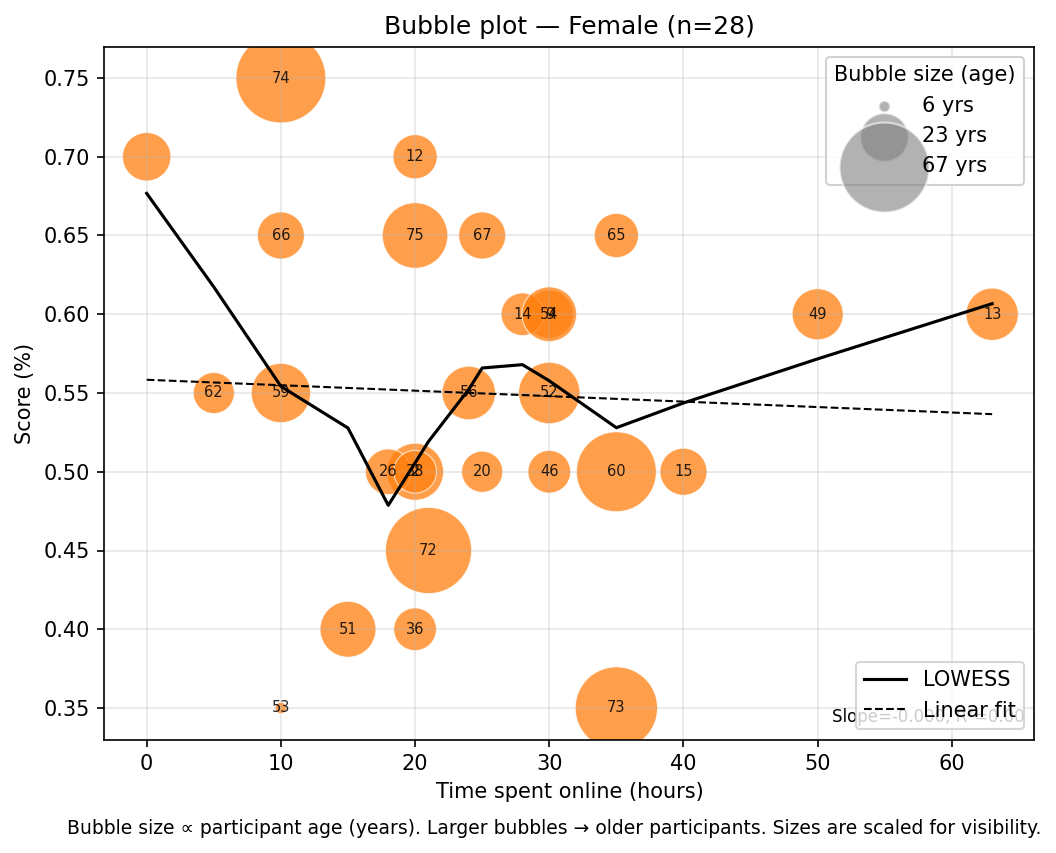

**Takeaway — Female**
n = 28
Sample size sufficient for descriptive comparison (n >= 10).
No meaningful linear trend detected.

Wrote bubble plot for Male -> /workspaces/DS_FinalProject/outputs/models/plots/gender/Male/bubble.png


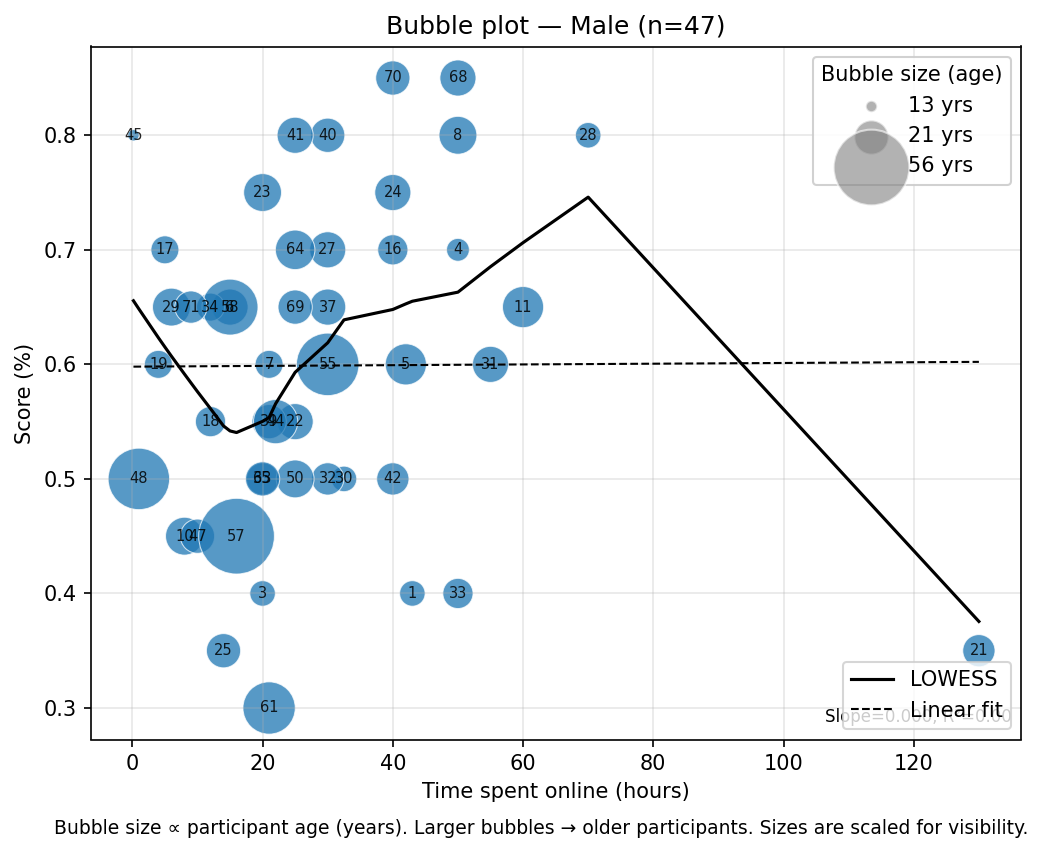

**Takeaway — Male**
n = 47
Sample size sufficient for descriptive comparison (n >= 10).
No meaningful linear trend detected.

In [ ]:
# Cell 3: Create bubble plots for each gender (time_spent_hours vs score_pct)
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display, Markdown
import pandas as pd

# LOWESS smoother (statsmodels) — use if available
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    has_lowess = True
except Exception:
    has_lowess = False

cleaned_path = ROOT / 'data' / 'cleaned_dataset.csv'
plots_root = ROOT / 'outputs' / 'models' / 'plots' / 'gender'
plots_root.mkdir(parents=True, exist_ok=True)

if not cleaned_path.exists():
    display(Markdown(f'**Cleaned dataset not found at {cleaned_path}.** Run `src/cleaning.py` then re-run this cell.'))
else:
    df = pd.read_csv(cleaned_path)
    # normalize gender and create numeric short IDs for readability
    df['gender'] = df.get('gender', 'Unknown').astype(str).str.strip()
    df = df.reset_index(drop=True)
    df['short_id'] = (df.index + 1).astype(int)  # 1..N mapping for easier annotation

    df['time_spent_hours'] = pd.to_numeric(df.get('time_spent_hours', pd.NA), errors='coerce')
    df['score_pct'] = pd.to_numeric(df.get('score_pct', pd.NA), errors='coerce')
    df['age'] = pd.to_numeric(df.get('age', pd.NA), errors='coerce')

    genders = sorted(df['gender'].dropna().unique(), key=lambda x: str(x))
    for gender in genders:
        gdf = df[df['gender'] == gender].copy()
        outdir = plots_root / str(gender)
        outdir.mkdir(parents=True, exist_ok=True)
        fname = outdir / 'bubble.png'

        plt.figure(figsize=(8,6))
        if gdf.empty:
            plt.text(0.5,0.5,f'No data for {gender}', ha='center')
            plt.axis('off')
            plt.savefig(fname, bbox_inches='tight')
            plt.close()
            print('Wrote placeholder for', gender, '->', fname)
            continue

        x = pd.to_numeric(gdf['time_spent_hours'], errors='coerce').fillna(0).values
        y = pd.to_numeric(gdf['score_pct'], errors='coerce').fillna(0).values
        ages = pd.to_numeric(gdf['age'], errors='coerce')
        ages_filled = ages.fillna(ages.median() if not ages.dropna().empty else 30).astype(float)
        # sizes scaled for visibility; ensure non-zero
        sizes = (ages_filled - ages_filled.min() + 1) * 30

        palette = {'Male':'#1f77b4','Female':'#ff7f0e'}
        color = palette.get(str(gender), '#2ca02c')

        sc = plt.scatter(x, y, s=sizes, c=color, alpha=0.75, edgecolors='w', linewidth=0.5)

        # create a bubble-size legend: pick representative ages (min, median, max)
        if not ages.dropna().empty:
            rep_ages = [int(ages.min()), int(ages.median()), int(ages.max())]
        else:
            rep_ages = [30, 45, 60]
        rep_sizes = [(a - ages_filled.min() + 1) * 30 for a in rep_ages]
        # plot legend handles
        handles = [plt.scatter([], [], s=s, c='gray', alpha=0.6, edgecolors='w') for s in rep_sizes]
        labels = [f'{a} yrs' for a in rep_ages]
        legend1 = plt.legend(handles, labels, title='Bubble size (age)', loc='upper right', framealpha=0.9)
        plt.gca().add_artist(legend1)

        # annotate points with anonymized numeric short ID
        for _, row in gdf.iterrows():
            pid = row.get('short_id', '')
            try:
                plt.annotate(str(int(pid)), (row.get('time_spent_hours',0), row.get('score_pct',0)), fontsize=7, alpha=0.85, ha='center', va='center')
            except Exception:
                pass

        # LOWESS smoothing (preferred) and linear fit for interpretability
        mask = (~np.isnan(x)) & (~np.isnan(y))
        if mask.sum() >= 3 and has_lowess:
            try:
                sm = lowess(y[mask], x[mask], frac=0.5)
                plt.plot(sm[:,0], sm[:,1], color='black', linewidth=1.5, label='LOWESS')
            except Exception:
                pass
        # always show linear dashed fit when enough points
        if mask.sum() >= 2:
            coef = np.polyfit(x[mask], y[mask], 1)
            x_line = np.linspace(x[mask].min(), x[mask].max(), 200)
            y_line = np.polyval(coef, x_line)
            plt.plot(x_line, y_line, color='k', linestyle='--', linewidth=1, label='Linear fit')
            y_pred = np.polyval(coef, x[mask])
            ss_res = ((y[mask] - y_pred) ** 2).sum()
            ss_tot = ((y[mask] - y[mask].mean()) ** 2).sum()
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0
            plt.text(0.99, 0.02, f'Slope={coef[0]:.3f}, R²={r2:.2f}', ha='right', va='bottom', transform=plt.gca().transAxes, fontsize=8)
        else:
            plt.text(0.5,0.02,'Insufficient points for fit', ha='center', fontsize=8, transform=plt.gca().transAxes)

        plt.xlabel('Time spent online (hours)')
        plt.ylabel('Score (%)')
        plt.title(f'Bubble plot — {gender} (n={len(gdf)})')
        plt.grid(True, alpha=0.3)
        fig = plt.gcf()
        fig.text(0.5, 0.005, 'Bubble size ∝ participant age (years). Larger bubbles → older participants. Sizes are scaled for visibility.', ha='center', fontsize=9)
        plt.legend(loc='lower right')
        plt.savefig(fname, bbox_inches='tight', dpi=150)
        plt.close()
        print('Wrote bubble plot for', gender, '->', fname)
        display(Image(str(fname)))

        # Short autogenerated takeaway per gender
        take = []
        take.append(f'**Takeaway — {gender}**')
        take.append(f'n = {len(gdf)}')
        if mask.sum() < 10:
            take.append('Small sample (n < 10); metrics unstable — descriptive only.')
        else:
            take.append('Sample size sufficient for descriptive comparison (n >= 10).')
        # simple directionality from slope if available
        if mask.sum() >= 2:
            slope = coef[0]
            if slope > 0.01:
                take.append('Slight positive relationship: more time online → higher score (weak).')
            elif slope < -0.01:
                take.append('Slight negative relationship: more time online → lower score (weak).')
            else:
                take.append('No meaningful linear trend detected.')
        display(Markdown('\n'.join(take)))

In [9]:
# Cell 3.5: Compare gender aggregates to overall aggregated metrics
import pandas as pd
from IPython.display import display, Markdown
# Build overall aggregated metrics from subgroup CSV (weighted by n)
sub_csv = ROOT / 'outputs' / 'models' / 'subgroup_model_metrics.csv'
if not sub_csv.exists():
    display(Markdown('**No subgroup metrics CSV found; cannot compute overall aggregate.**'))
else:
    sub = pd.read_csv(sub_csv)
    for c in ['n','pos','accuracy','precision','recall','f1','roc_auc']:
        if c in sub.columns: sub[c] = pd.to_numeric(sub[c], errors='coerce')
    if 'pr_auc' not in sub.columns:
        # try summary plots CSV
        ssum = ROOT / 'outputs' / 'models' / 'plots' / 'subgroup_model_summary.csv'
        if ssum.exists():
            ssumdf = pd.read_csv(ssum)
            sub = sub.merge(ssumdf[['age_range','gender','pr_auc']], on=['age_range','gender'], how='left')
        else:
            sub['pr_auc'] = pd.NA
    # compute weighted overall metrics
    total_n = sub['n'].sum() if 'n' in sub.columns else len(sub)
    def wavg(s):
        w = sub['n'].fillna(0)
        if w.sum()==0: return pd.NA
        return (s.fillna(0)*w).sum()/w.sum()
    overall = {'gender':'Overall','n':int(total_n),'pos':int(sub['pos'].sum()) if 'pos' in sub.columns else pd.NA}
    for m in ['accuracy','precision','recall','f1','roc_auc','pr_auc']:
        if m in sub.columns: overall[m]=round(wavg(sub[m]),3)
        else: overall[m]=pd.NA
    # read saved gender summary and append overall row for side-by-side display
    gfile = ROOT / 'outputs' / 'models' / 'gender_summary_metrics.csv'
    if gfile.exists():
        gdf = pd.read_csv(gfile)
        comp = pd.concat([pd.DataFrame([overall]), gdf], ignore_index=True, sort=False)
        display(Markdown('## Overall vs Gender comparison'))
        display(comp[['gender','n','pos','accuracy','precision','recall','f1','roc_auc','pr_auc','note']])
        # save comparison CSV
        outcompare = ROOT / 'outputs' / 'models' / 'gender_vs_overall_metrics.csv'
        comp.to_csv(outcompare, index=False)
        print(f'Wrote comparison CSV to {outcompare}')
    else:
        display(Markdown('No gender summary CSV found to compare; run the aggregation cell first.'))

## Overall vs Gender comparison

,gender,n,pos,accuracy,precision,recall,f1,roc_auc,pr_auc,note
0,Overall,62,34,0.629,0.573,0.564,0.540,0.595,0.652,NaN
1,Female,20,13,0.750,0.783,0.825,0.793,0.725,0.846,n=20; ROC=0.725; PR=0.846
2,Male,42,21,0.571,0.473,0.440,0.419,0.533,0.560,n=42; ROC=0.533; PR=0.560


Wrote comparison CSV to /workspaces/DS_FinalProject/outputs/models/gender_vs_overall_metrics.csv


## Reproduce steps from project root
To regenerate inputs and plots, run the following from the repository root (use the project venv Python):

```bash
/workspaces/DS_FinalProject/.venv/bin/python src/cleaning.py
/workspaces/DS_FinalProject/.venv/bin/python src/subgroup_modeling.py --min-n 1
/workspaces/DS_FinalProject/.venv/bin/python src/plot_models.py
```